intro stuff here:
research question or hypothesis
system and motivation
assumptions and rules
experiments

some notes for experiments / analysis: values not specified take the baseline ONE_FACTOR_BASELINE in utils/experiments.py (demand 0.2, ns_share 0.5, turning 0.5, reaction_delay 0)

In [1]:
# the following code aggregates the results, averaging them across all trials
# data stores the raw data from the results
# avg_data stores the results averaged across all ten trials

with open("./sweep_results.csv", "r") as f:
    data=[]
    for test in f:
        data.append(test.split(","))

avg_data=[] # stores data averaged across seeds
cnt=0
for test in data:
    if cnt%10==0:
        tmp_data=[0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0]
        avg_data.append([test[0], test[1]])

    for i in range(len(test[2:])):
        tmp_data[i]+=float(test[2+i])

    cnt+=1
    if cnt%10==0:
        for value in tmp_data:
           avg_data[-1].append(value/10)

description of first experiment

vary traffic lights for fixed everything

Our first experiment is a very basic one. Every variable will remain constant, except for the type of traffic light used. This is to try to get an understanding of how the different types of lights work in a controlled setting.

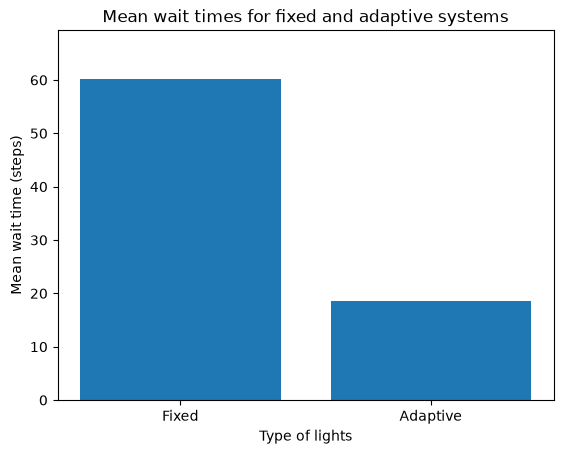

In [2]:
import matplotlib.pyplot as plt


results=[]
for item in avg_data[:3]:
    results.append(item[2])

Lights = ["Fixed", "Adaptive"]
Waits = [results[0], results[1]]

fig, ax = plt.subplots()
bar_container = ax.bar(Lights, Waits)

ax.set_xlabel("Type of lights")
ax.set_ylabel("Mean wait time (steps)")
ax.set_title("Mean wait times for fixed and adaptive systems")
ax.set_ylim(0, 1.15 * max(Waits))

plt.show()

analysis of results of first experiment



description of second experiment

change number of cars for varying traffic lights

To get better clarity on how the types of lights compare, the next experiment will vary the type of lights and the number of cars that pass through the intersection.

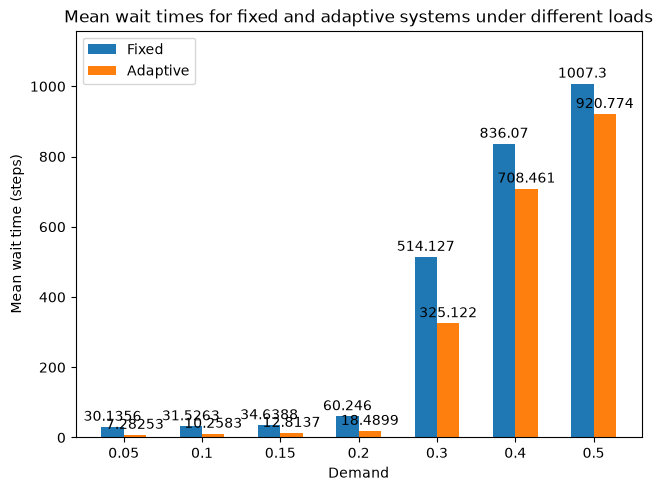

In [3]:
res=[]
for item in avg_data[2:16]:
    res.append(item[3])

demands = (0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5)
averages = { "Fixed": tuple(res[0:7]), "Adaptive": tuple(res[7:15])}

fig, ax = plt.subplots(layout="constrained")
res = ax.grouped_bar(averages, tick_labels=demands)
for container in res.bar_containers:
    ax.bar_label(container, padding=2)

ax.set_xlabel("Demand")
ax.set_ylabel("Mean wait time (steps)")
ax.set_title("Mean wait times for fixed and adaptive systems under different loads")
ax.legend(loc="upper left")
ax.set_ylim(0, 1.15 * max(max(v) for v in averages.values()))

plt.show()

analysis of second experiment

at demand 0.3 and greater, cars come in faster than they could possibly be cleared

description of third experiment

change relative density of intersections

To see how the types of intersection work on different types of load, the next experiment will change the distribution of cars across the intersection so that one side has more traffic than the other.

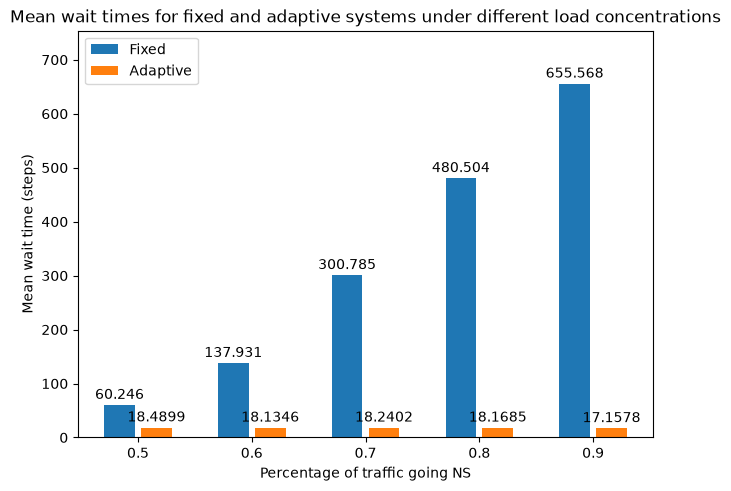

In [4]:
res=[]
for item in avg_data[16:26]:
    res.append(item[3])

demands = (0.5, 0.6, 0.7, 0.8, 0.9)
averages = { "Fixed": tuple(res[0:5]), "Adaptive": tuple(res[5:10])}

fig, ax = plt.subplots(layout="constrained")
res = ax.grouped_bar(averages, tick_labels=demands, bar_spacing=0.2)
for container in res.bar_containers:
    ax.bar_label(container, padding=2)

ax.set_xlabel("Percentage of traffic going NS")
ax.set_ylabel("Mean wait time (steps)")
ax.set_title("Mean wait times for fixed and adaptive systems under different load concentrations")
ax.legend(loc="upper left")
ax.set_ylim(0, 1.15 * max(max(v) for v in averages.values()))

plt.show()

analysis of results of third experiment

description of fourth experiment

change reaction delay

When traffic starts after a light turns green, cars naturally separate due to the reaction speeds of their drivers. For our next experiment, the reaction speeds will be varied.

note: in theory, reaction speeds should cause longer open times to be favoured as the total number of reaction-speed delays is reduced

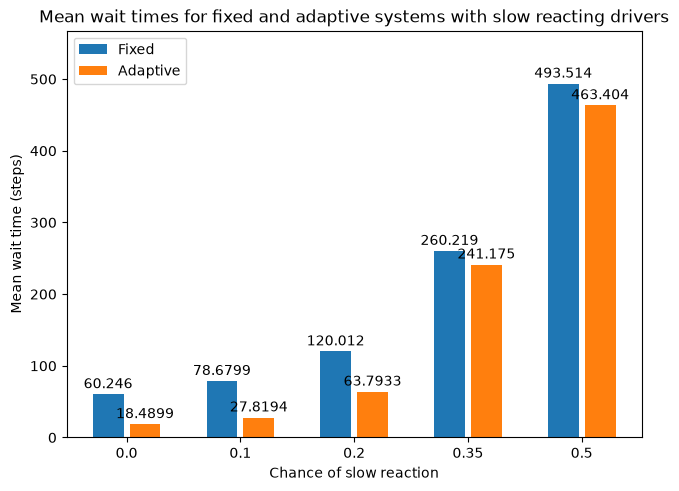

In [5]:
res=[]
for item in avg_data[26:36]:
    res.append(item[3])

demands = (0.0, 0.1, 0.2, 0.35, 0.5)
averages = { "Fixed": tuple(res[0:5]), "Adaptive": tuple(res[5:10])}

fig, ax = plt.subplots(layout="constrained")
res = ax.grouped_bar(averages, tick_labels=demands, bar_spacing=0.2)
for container in res.bar_containers:
    ax.bar_label(container, padding=2)

ax.set_xlabel("Chance of slow reaction")
ax.set_ylabel("Mean wait time (steps)")
ax.set_title("Mean wait times for fixed and adaptive systems with slow reacting drivers")
ax.legend(loc="upper left")
ax.set_ylim(0, 1.15 * max(max(v) for v in averages.values()))

plt.show()

analysis of results of fourth experiment

description of fifth experiment

alter proportions of turning cars

Depending on which direction they are turning, cars take longer or shorter to pass through the crossing. For our next experiment, the proportions of cars turning and staying straight will be changed to see how this impacts congestion.

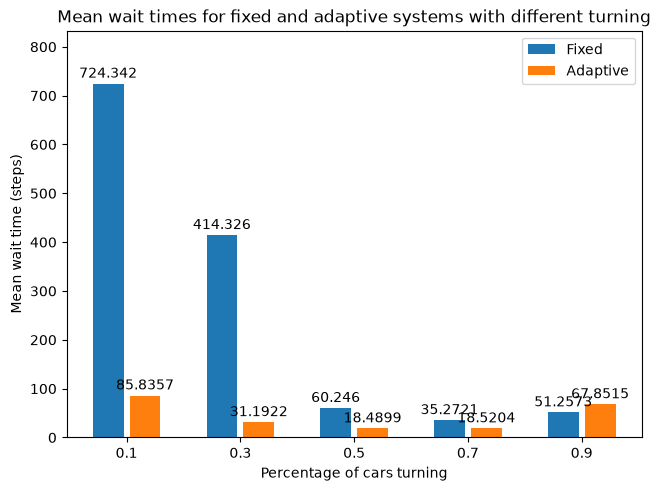

In [6]:
res=[]
for item in avg_data[36:46]:
    res.append(item[3])

demands = (0.1, 0.3, 0.5, 0.7, 0.9)
averages = { "Fixed": tuple(res[0:5]), "Adaptive": tuple(res[5:10])}

fig, ax = plt.subplots(layout="constrained")
res = ax.grouped_bar(averages, tick_labels=demands, bar_spacing=0.2)
for container in res.bar_containers:
    ax.bar_label(container, padding=2)

ax.set_xlabel("Percentage of cars turning")
ax.set_ylabel("Mean wait time (steps)")
ax.set_title("Mean wait times for fixed and adaptive systems with different turning")
ax.legend(loc="upper right")
ax.set_ylim(0, 1.15 * max(max(v) for v in averages.values()))

plt.show()

analysis of fifth experiment

Overall analysis of results, limitations and possible extensions